# Train weather-only profiles 

| Profile | Supplied label meaning |
|---|---|
| Low | Day −3 |
| Medium | Day −2 |
| High | Day −1 and landfall day |


## 1. Settings

In [1]:
from pathlib import Path

ROOT = Path.cwd()
# Notebook is now located directly in Typhoon/. Support running from
# either the Typhoon directory or the containing repository directory.
if ROOT.name == "training":
    ROOT = ROOT.parent
elif (ROOT / "Typhoon" / "data").is_dir():
    ROOT = ROOT / "Typhoon"
if not (ROOT / "data" / "processed").is_dir():
    raise FileNotFoundError(
        "Run the notebook from Typhoon/ (or its parent directory). "
        f"Could not locate data/processed under {ROOT}"
    )
EXPERIMENT_ID = "final_test2"
INPUT_FILE = ROOT / "data/processed/jma_day3_to_landfall_with_weather_prefecture.csv"
OUTPUT_DIR = ROOT / "trained_models/risk" / EXPERIMENT_ID
LOG_DIR = ROOT / "experiment_logs/risk" / EXPERIMENT_ID

TEST_SIZE = 0.20
SEED = 42
REMOVE_FEATURES = [
    
        "pressure_msl_mean",
    ]  # e.g. ["rain_sum"]
MODEL_PARAMS = {
    "Random Forest": {"n_estimators": 300, "max_depth": None},
    "CART": {"max_depth": None},
    "Gradient Boosting": {"n_estimators": 100, "learning_rate": 0.1},
    "SVM": {"C": 1.0, "kernel": "rbf"},
}
OVERWRITE_OUTPUTS = False

# Optional: CSV containing weather to classify (for example, predicted daily weather).
# Leave None to demonstrate a historical row included in the final model fit.
PREDICTION_FILE = None
MODEL_TO_VIEW = "Random Forest"
ROW_TO_VIEW = 0


## 2. Imports and checks

In [2]:
# Install once if needed:
# %pip install pandas numpy matplotlib scikit-learn joblib
%matplotlib inline
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

assert 0 < TEST_SIZE < 1
if not INPUT_FILE.is_file():
    raise FileNotFoundError("Set INPUT_FILE to your existing historical weather/event CSV.")
for folder in [OUTPUT_DIR, LOG_DIR]:
    if folder.exists() and any(folder.iterdir()) and not OVERWRITE_OUTPUTS:
        raise FileExistsError(f"Choose a new EXPERIMENT_ID, or enable OVERWRITE_OUTPUTS: {folder}")


FileExistsError: Choose a new EXPERIMENT_ID, or enable OVERWRITE_OUTPUTS: c:\Users\IAN\Desktop\SEM (SWIN)\SEM 2\COS30049-Computing Technology Innovation Project\Assignments\Dev\Group1_COS30049_Computing-Technology-Innovation\Typhoon\trained_models\risk\final_test2

## 3. Load every uploaded row and its existing label

In [ ]:
df = pd.read_csv(INPUT_FILE, encoding="utf-8-sig")
INPUT_ROW_COUNT = len(df)
required = {"intl_id", "landfall_event_id", "date", "days_before_landfall", "risk"}
if df.empty or not required.issubset(df.columns):
    raise ValueError(f"Input requires nonempty data with {sorted(required)}.")
if df[list(required)].isna().any().any():
    raise ValueError("Storm/event IDs, dates, day labels and risk labels cannot be missing.")
df["source_row_number"] = np.arange(1, INPUT_ROW_COUNT + 1)
df["date"] = pd.to_datetime(df["date"], errors="raise").dt.normalize()
df["days_before_landfall"] = pd.to_numeric(df.days_before_landfall, errors="raise")
df["source_risk"] = df["risk"]
LABEL_NAMES = {"LOW": "Low", "MODERATE": "Medium", "MEDIUM": "Medium", "HIGH": "High"}
df["risk"] = df.risk.astype(str).str.strip().str.upper().map(LABEL_NAMES)
if df.risk.isna().any():
    raise ValueError("Existing labels must be Low, Moderate/Medium or High.")
df = df.sort_values(["date", "landfall_event_id"]).reset_index(drop=True)
if df.duplicated(["landfall_event_id", "date"]).any():
    raise ValueError("Duplicate event/date records; inspect them before training. No rows were dropped.")
if (df.groupby("landfall_event_id").intl_id.nunique() != 1).any():
    raise ValueError("Each event must belong to one storm.")
assert len(df) == INPUT_ROW_COUNT
print(f"Loaded and retained all {INPUT_ROW_COUNT} data rows | {df.intl_id.nunique()} storms | {df.landfall_event_id.nunique()} events")
print("Historical dates:", df.date.min().date(), "to", df.date.max().date())
print("Landfall-day rows included:", int(df.days_before_landfall.eq(0).sum()))
display(df.risk.value_counts().reindex(["Low", "Medium", "High"]).rename("rows"))
display(df[["source_row_number", "date", "landfall_event_id", "days_before_landfall", "source_risk", "risk"]].head())


Loaded and retained all 788 data rows | 102 storms | 200 events
Historical dates: 2000-09-09 to 2026-06-26
Landfall-day rows included: 200


risk
Low       189
Medium    199
High      400
Name: rows, dtype: int64

,source_row_number,date,landfall_event_id,days_before_landfall,source_risk,risk
0,1,2000-09-09,0014_2000091210,3,Low,Low
1,2,2000-09-10,0014_2000091210,2,Moderate,Medium
2,3,2000-09-11,0014_2000091210,1,High,High
3,4,2000-09-12,0014_2000091210,0,High,High
4,5,2001-08-18,0111_2001082110,3,Low,Low


## 4. Weather inputs only

In [ ]:
WEATHER = [
    "temperature_2m_mean",
    "temperature_2m_max",
    "temperature_2m_min",
    "relative_humidity_2m_mean",
    "relative_humidity_2m_max",
    "relative_humidity_2m_min",
    "dew_point_2m_mean",
    "dew_point_2m_max",
    "dew_point_2m_min",
    "precipitation_sum",
    "rain_sum",
    "precipitation_hours",
    "cloud_cover_mean",
    "cloud_cover_max",
    "cloud_cover_min",
    "pressure_msl_mean",
    "pressure_msl_max",
    "pressure_msl_min",
    "surface_pressure_mean",
    "surface_pressure_max",
    "surface_pressure_min",
    "wind_speed_10m_mean",
    "wind_speed_10m_max",
    "wind_speed_10m_min",
    "wind_gusts_10m_mean",
    "wind_gusts_10m_max",
    "wind_gusts_10m_min",
    "wind_direction_10m_dominant",
    "shortwave_radiation_sum"
]
unknown = set(REMOVE_FEATURES) - set(WEATHER)
if unknown:
    raise ValueError(f"Unknown weather names: {sorted(unknown)}")
FEATURES = [c for c in WEATHER if c not in REMOVE_FEATURES]
if not FEATURES:
    raise ValueError("Keep at least one weather feature.")
missing = set(FEATURES) - set(df.columns)
if missing:
    raise ValueError(f"Missing weather attributes: {sorted(missing)}")
for name in FEATURES:
    df[name] = pd.to_numeric(df[name], errors="raise")
if np.isinf(df[FEATURES].to_numpy()).any() or df[FEATURES].isna().all(axis=1).any():
    raise ValueError("Infinite inputs or rows with no weather observations.")
print("Raw weather inputs:", len(FEATURES))
display(pd.DataFrame({"weather_feature": FEATURES}))
print("Missing weather cells:", int(df[FEATURES].isna().sum().sum()))


Raw weather inputs: 28


,weather_feature
0,temperature_2m_mean
1,temperature_2m_max
2,temperature_2m_min
3,relative_humidity_2m_mean
4,relative_humidity_2m_max
5,relative_humidity_2m_min
6,dew_point_2m_mean
7,dew_point_2m_max
8,dew_point_2m_min
9,precipitation_sum


Missing weather cells: 0


## 5. Hold out whole typhoons for evaluation
All events and rows belonging to the same storm stay in one split. No rows are excluded: the splits partition the full dataset. The final saved models will subsequently be refitted on all rows.

In [ ]:
groups = df.intl_id.astype(str)
if groups.nunique() < 4:
    raise ValueError("Need at least four independent storms for a useful holdout.")
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED).split(df, groups=groups))
train_df, test_df = df.iloc[train_idx].copy(), df.iloc[test_idx].copy()
assert len(train_df) + len(test_df) == INPUT_ROW_COUNT
assert set(train_df.source_row_number) | set(test_df.source_row_number) == set(df.source_row_number)
assert set(train_df.intl_id).isdisjoint(test_df.intl_id)
assert set(train_df.landfall_event_id).isdisjoint(test_df.landfall_event_id)
if set(train_df.risk) != {"Low", "Medium", "High"}:
    raise ValueError("Training split must contain all three profiles.")
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df.risk, test_df.risk
if X_train.isna().all().any():
    raise ValueError("A training weather column has no observations; remove it or restore its values.")
print(f"Train: {len(train_df)} rows | Test: {len(test_df)} rows | Shared storms: 0")
display(pd.concat([y_train.value_counts().rename("train"), y_test.value_counts().rename("test")], axis=1).reindex(["Low", "Medium", "High"]).fillna(0))


Train: 642 rows | Test: 146 rows | Shared storms: 0


,train,test
risk,,
Low,154,35
Medium,162,37
High,326,74


## 6. Preprocessing and classification models
Weather variables are imputed and standardized. Wind direction is encoded as sine/cosine so 359° and 1° remain close. The saved model includes this preprocessing; prediction still takes the raw weather columns.

In [ ]:
ANGLE = "wind_direction_10m_dominant"
NUMERIC = [c for c in FEATURES if c != ANGLE]
transformers = []
if NUMERIC:
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    transformers.append(("weather", numeric, NUMERIC))
if ANGLE in FEATURES:
    for name, function in [("direction_sin", np.sin), ("direction_cos", np.cos)]:
        circular = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("radians", FunctionTransformer(np.deg2rad)),
            ("angle", FunctionTransformer(function)),
        ])
        transformers.append((name, circular, [ANGLE]))
preprocessor = ColumnTransformer(transformers)
models = {
    "Random Forest": RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=2, **MODEL_PARAMS["Random Forest"]),
    "CART": DecisionTreeClassifier(random_state=SEED, class_weight="balanced", **MODEL_PARAMS["CART"]),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED, **MODEL_PARAMS["Gradient Boosting"]),
    "SVM": SVC(random_state=SEED, class_weight="balanced", probability=True, **MODEL_PARAMS["SVM"]),
}
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)


## 7. Evaluate the models on heldout storms
Scores describe the supplied event profiles, including landfall-day weather. These evaluation models are separate from the final models fitted to the entire dataset. Use separate validation storms for parameter tuning.


Training: Random Forest
              precision    recall  f1-score   support

         Low      0.414     0.343     0.375        35
      Medium      0.412     0.378     0.394        37
        High      0.723     0.811     0.764        74

    accuracy                          0.589       146
   macro avg      0.516     0.511     0.511       146
weighted avg      0.570     0.589     0.577       146



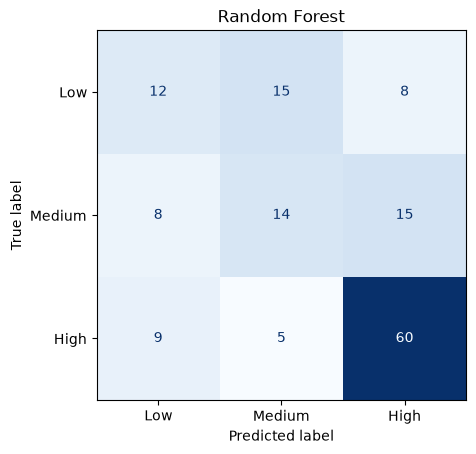


Training: CART
              precision    recall  f1-score   support

         Low      0.318     0.200     0.246        35
      Medium      0.356     0.432     0.390        37
        High      0.620     0.662     0.641        74

    accuracy                          0.493       146
   macro avg      0.431     0.432     0.425       146
weighted avg      0.481     0.493     0.482       146



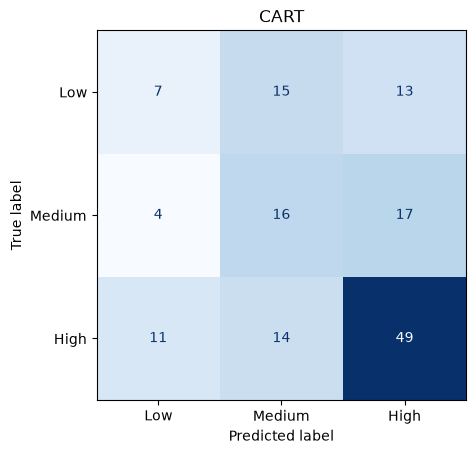


Training: Gradient Boosting
              precision    recall  f1-score   support

         Low      0.346     0.257     0.295        35
      Medium      0.323     0.270     0.294        37
        High      0.697     0.838     0.761        74

    accuracy                          0.555       146
   macro avg      0.455     0.455     0.450       146
weighted avg      0.518     0.555     0.531       146



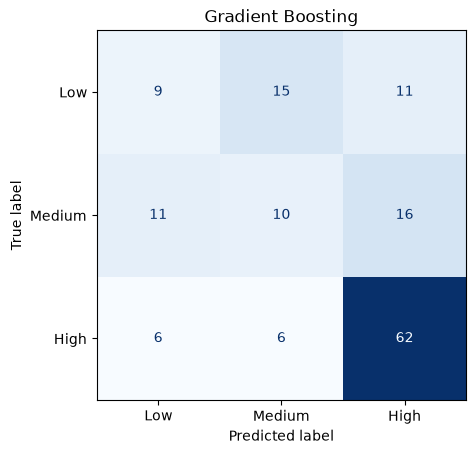


Training: SVM
              precision    recall  f1-score   support

         Low      0.340     0.514     0.409        35
      Medium      0.282     0.297     0.289        37
        High      0.796     0.581     0.672        74

    accuracy                          0.493       146
   macro avg      0.473     0.464     0.457       146
weighted avg      0.556     0.493     0.512       146



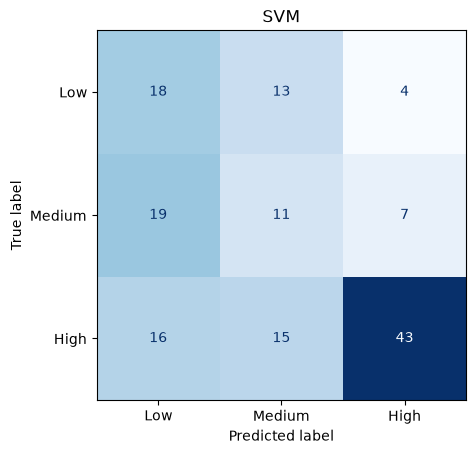

,Model,Accuracy,Balanced accuracy,Macro F1
0,Random Forest,0.589041,0.510682,0.511232
1,SVM,0.493151,0.464221,0.456813
2,Gradient Boosting,0.554795,0.455084,0.449979
3,CART,0.493151,0.431532,0.425460


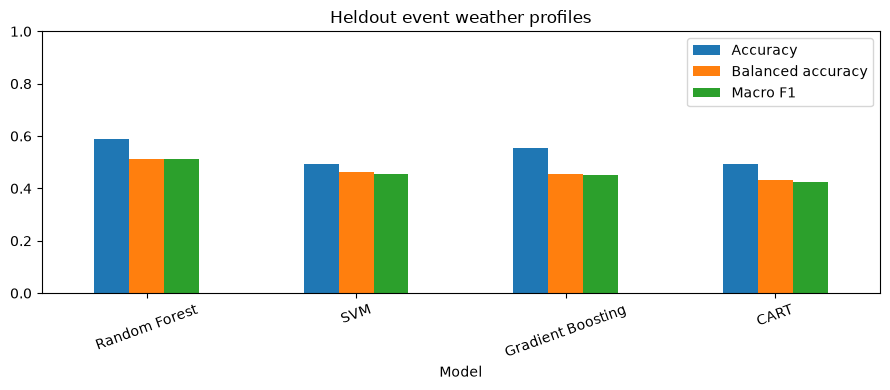

In [ ]:
comparison = []
trained_models = {}
metadata = [c for c in ["date", "intl_id", "landfall_event_id", "storm_name", "days_before_landfall", "risk"] if c in test_df]
all_predictions = test_df[metadata].copy()
CLASS_ORDER = ["Low", "Medium", "High"]
for name, estimator in models.items():
    print(f"\nTraining: {name}")
    classifier = Pipeline([("preprocessor", clone(preprocessor)), ("model", estimator)])
    classifier.fit(X_train, y_train)
    predicted = classifier.predict(X_test)
    trained_models[name] = classifier
    comparison.append({"Model": name, "Accuracy": accuracy_score(y_test, predicted),
                       "Balanced accuracy": balanced_accuracy_score(y_test, predicted),
                       "Macro F1": f1_score(y_test, predicted, labels=CLASS_ORDER, average="macro", zero_division=0)})
    print(classification_report(y_test, predicted, labels=CLASS_ORDER, digits=3, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, labels=CLASS_ORDER, cmap="Blues", colorbar=False)
    plt.title(name)
    filename = name.lower().replace(" ", "_")
    plt.savefig(LOG_DIR / f"{filename}_confusion.png", dpi=120, bbox_inches="tight")
    plt.show()
    
    all_predictions[name] = predicted

comparison = pd.DataFrame(comparison).sort_values("Balanced accuracy", ascending=False).reset_index(drop=True)
display(comparison)
comparison.set_index("Model")[["Accuracy", "Balanced accuracy", "Macro F1"]].plot.bar(figsize=(9, 4), ylim=(0, 1))
plt.title("Heldout event weather profiles")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(LOG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()


## 8. Refit the final prediction models on all rows

The heldout evaluation above stays independent. Each final saved classifier is now fitted on the **entire CSV**, including the rows previously held out for evaluation. Preprocessing is refitted as part of each model. This fulfills full-data training; the earlier test scores do not evaluate these refitted models.

In [ ]:
deployment_models = {}
for name, estimator in models.items():
    final_model = Pipeline([("preprocessor", clone(preprocessor)), ("model", clone(estimator))])
    final_model.fit(df[FEATURES], df.risk)
    deployment_models[name] = final_model
    filename = name.lower().replace(" ", "_")
    joblib.dump(final_model, OUTPUT_DIR / f"{filename}_model.joblib")
    print(f"Saved {name}: fitted on all {len(df)} rows")
df.to_csv(OUTPUT_DIR / "full_training_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")


Saved Random Forest: fitted on all 788 rows
Saved CART: fitted on all 788 rows
Saved Gradient Boosting: fitted on all 788 rows
Saved SVM: fitted on all 788 rows


## 9. Predict from weather conditions
Set `PREDICTION_FILE` in the settings cell to your weather CSV. Prediction uses the **final full-data model**. When it is `None`, the example is a historical row already included in that model's training, not an independent accuracy test. The file needs selected weather columns only. Class probabilities describe event-weather profiles, not typhoon occurrence probability.

In [ ]:
def predict_weather(weather_rows, model_name=MODEL_TO_VIEW):
    if model_name not in deployment_models:
        raise ValueError(f"Choose one of {list(deployment_models)}.")
    missing = set(FEATURES) - set(weather_rows.columns)
    if missing:
        raise ValueError(f"Prediction input lacks weather attributes: {sorted(missing)}")
    inputs = weather_rows[FEATURES].apply(pd.to_numeric, errors="raise")
    if inputs.empty or np.isinf(inputs.to_numpy()).any() or inputs.isna().all(axis=1).any():
        raise ValueError("Prediction requires nonempty, finite weather observations.")
    classifier = deployment_models[model_name]
    keep = [c for c in ["date", "prefecture", "town", "intl_id", "landfall_event_id"] if c in weather_rows]
    result = weather_rows[keep].copy().reset_index(drop=True)
    result["matched_weather_profile"] = classifier.predict(inputs)
    probabilities = classifier.predict_proba(inputs)
    for i, label in enumerate(classifier.classes_):
        result[f"profile_probability_{label.lower()}"] = probabilities[:, i]
    return result

if PREDICTION_FILE is None:
    if not 0 <= ROW_TO_VIEW < len(df):
        raise IndexError("ROW_TO_VIEW is outside the full historical dataset.")
    prediction_weather = df.iloc[[ROW_TO_VIEW]].copy()
    print("Historical example included in final training; source label:", prediction_weather.risk.iloc[0])
else:
    prediction_weather = pd.read_csv(PREDICTION_FILE, encoding="utf-8-sig")
weather_predictions = predict_weather(prediction_weather)
display(weather_predictions.head(10))
weather_predictions.to_csv(OUTPUT_DIR / "weather_profile_predictions.csv", index=False, encoding="utf-8-sig")


Historical example included in final training; source label: Low


,date,intl_id,landfall_event_id,matched_weather_profile,profile_probability_high,profile_probability_low,profile_probability_medium
0,2000-09-09,14,0014_2000091210,Low,0.07798,0.787376,0.134644


## 10. See similar historical weather
This table shows the closest records from the **full historical dataset**, using the final model's weather preprocessing. For an existing historical-row query, the exact same row can appear at zero distance. The table is an explanation of similarity, not an independent test.

In [ ]:
matcher_preprocessor = deployment_models[MODEL_TO_VIEW].named_steps["preprocessor"]
reference_weather = matcher_preprocessor.transform(df[FEATURES])
query_weather = matcher_preprocessor.transform(prediction_weather[FEATURES].apply(pd.to_numeric, errors="raise").iloc[[0]])
matcher = NearestNeighbors(n_neighbors=min(5, len(df))).fit(reference_weather)
distances, indices = matcher.kneighbors(query_weather)
columns = [c for c in ["date", "storm_name", "landfall_event_id", "days_before_landfall", "risk"] if c in df]
weather_matches = df.iloc[indices[0]][columns].copy()
weather_matches.insert(0, "weather_distance", distances[0])
display(weather_matches)
weather_matches.to_csv(OUTPUT_DIR / "similar_historical_weather.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")


,weather_distance,date,storm_name,landfall_event_id,days_before_landfall,risk
0,0.000000,2000-09-09,SAOMAI,0014_2000091210,3,Low
29,1.447011,2001-09-08,DANAS,0115_2001091100,3,Low
162,2.096983,2004-07-28,NAMTHEUN,0410_2004073112,3,Low
161,2.096983,2004-07-28,NAMTHEUN,0410_2004073107,3,Low
30,2.229507,2001-09-09,DANAS,0115_2001091100,2,Medium


## 11. Save evaluation and full-data training records

In [ ]:
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
all_predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
train_df.to_csv(OUTPUT_DIR / "training_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
test_df.to_csv(OUTPUT_DIR / "testing_set.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
config = {"features": FEATURES, "classes": CLASS_ORDER, "model_parameters": MODEL_PARAMS, "seed": SEED,
          "input": str(INPUT_FILE), "row_policy": "all CSV rows; no date/day filtering",
          "input_rows": INPUT_ROW_COUNT, "deployment_training_rows": len(df),
          "evaluation_train_rows": len(train_df), "evaluation_test_rows": len(test_df),
          "included_days_before_landfall": sorted(df.days_before_landfall.unique().tolist()),
          "label_definition": {"Low": "Day -3", "Medium": "Day -2", "High": "Day -1 and landfall day"},
          "test_storms": sorted(test_df.intl_id.astype(str).unique().tolist()),
          "input_contract": "raw weather only; circular wind transform included in saved pipeline",
          "interpretation": "Similarity to event weather, not probability of typhoon occurrence.",
          "evaluation_note": "Scores use heldout-storm models; final saved models are refitted on all rows."}
for folder in [OUTPUT_DIR, LOG_DIR]:
    (folder / "config.json").write_text(json.dumps(config, indent=2), encoding="utf-8")
comparison.to_csv(LOG_DIR / "model_comparison.csv", index=False)
print("Saved models and prediction tables:", OUTPUT_DIR)
print("Saved experiment logs:", LOG_DIR)
display(all_predictions.head(10))


Saved models and prediction tables: c:\Users\IAN\Desktop\SEM (SWIN)\SEM 2\COS30049-Computing Technology Innovation Project\Assignments\Dev\Group1_COS30049_Computing-Technology-Innovation\Typhoon\trained_models\risk\final_test2
Saved experiment logs: c:\Users\IAN\Desktop\SEM (SWIN)\SEM 2\COS30049-Computing Technology Innovation Project\Assignments\Dev\Group1_COS30049_Computing-Technology-Innovation\Typhoon\experiment_logs\risk\final_test2


,date,intl_id,landfall_event_id,storm_name,days_before_landfall,risk,Random Forest,CART,Gradient Boosting,SVM
0,2000-09-09,14,0014_2000091210,SAOMAI,3,Low,Medium,Medium,Medium,Medium
1,2000-09-10,14,0014_2000091210,SAOMAI,2,Medium,Low,Low,Low,Low
2,2000-09-11,14,0014_2000091210,SAOMAI,1,High,Low,Low,Medium,Low
3,2000-09-12,14,0014_2000091210,SAOMAI,0,High,High,High,High,Low
105,2003-06-14,306,0306_2003061720,SOUDELOR,3,Low,Low,Low,Low,Low
106,2003-06-15,306,0306_2003061720,SOUDELOR,2,Medium,Low,Medium,Low,Low
107,2003-06-16,306,0306_2003061720,SOUDELOR,1,High,Low,Medium,Low,Low
108,2003-06-16,306,0306_2003061904,SOUDELOR,3,Low,Low,Medium,Low,Low
109,2003-06-17,306,0306_2003061720,SOUDELOR,0,High,High,High,High,Medium
110,2003-06-17,306,0306_2003061904,SOUDELOR,2,Medium,High,High,High,High
